# 08 - Who Is Underinsured, and What Does It Cost Them?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**Question:** Which flooded buildings had building coverage that was too low for their value, and how much flood damage was left
unpaid because of it?

**Words we use**
- **Replacement cost:** what it would cost to rebuild the building (`buildingReplacementCost`, estimated by the adjuster).
- **Insurance-to-value (ITV):** building coverage ÷ replacement cost. 1.0 means the building is insured for its full rebuilding cost.
- **NFIP limit:** the most building coverage the NFIP sells: **$250,000** for a home (1-4 families, mobile home, single unit),
  **$500,000** for a building with 5+ apartments or a business, and **$250,000 per unit** for a condo association building.

**When is a building underinsured?** NFIP rules ask for coverage of at least **80% of the replacement cost, or the NFIP limit if that is
lower** (otherwise the claim is not paid at full replacement cost). So we put every claim into one of three groups:

| Group | Meaning |
|---|---|
| **well insured** | coverage ≥ 80% of the replacement cost |
| **at the NFIP limit** | coverage < 80% of the replacement cost, but the owner already has the maximum the NFIP sells; the gap is not their choice |
| **underinsured by choice** | coverage < 80% of the replacement cost **and** below the NFIP limit: the owner could have bought more |

**Plan**
1. Prepare the data
2. How much of the building value is insured?
3. The three groups
4. What does it cost? Damage that was not covered
5. Who is underinsured by choice?
6. Did it change over time or with Risk Rating 2.0?
7. Our answer

## 1. Prepare the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
SEED = 42

df = pd.read_parquet('data/claims_clean.parquet')
raw = pd.read_parquet('/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet', columns=['id', 'buildingReplacementCost'])
df = df.merge(raw, on='id', how='left')
df['buildingReplacementCost'] = df['buildingReplacementCost'].astype(float)

OCC = {11: 'single family', 12: '2-4 units', 13: '5+ units', 14: 'mobile home', 15: 'condo building', 16: 'unit in building',
       17: 'non-res. mobile', 18: 'non-residential', 19: 'non-res. unit'}
df['occ_code'] = pd.to_numeric(df['occupancy'], errors='coerce')
df['occupancy_name'] = df['occ_code'].map(OCC).fillna('unknown')

# NFIP limit for building coverage
cap = pd.Series(np.nan, index=df.index)
cap[df['occ_code'].isin([11, 12, 14, 16])] = 250_000
cap[df['occ_code'].isin([13, 17, 18, 19])] = 500_000
cap[df['occ_code'] == 15] = 250_000 * df['numberOfUnits'].clip(lower=1)
df['nfip_limit'] = cap

ok = (df['buildingReplacementCost'] > 0) & (df['totalBuildingInsuranceCoverage'] > 0) & df['nfip_limit'].notna()
print(f'Claims: {len(df):,}')
print(f'   with replacement cost > 0, coverage > 0 and a known occupancy: {ok.sum():,}')
d = df[ok].copy()
d['itv'] = d['totalBuildingInsuranceCoverage'] / d['buildingReplacementCost']
print(d['itv'].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).round(2))

Claims: 276,570
   with replacement cost > 0, coverage > 0 and a known occupancy: 218,764
count     218764.00
mean           8.86
std         2449.45
min            0.00
5%             0.16
25%            0.47
50%            0.74
75%            0.99
95%            1.46
max      1000000.00
Name: itv, dtype: float64


A few claims have a coverage **much bigger** than the replacement cost (ITV far above 1). An owner cannot get more than the building's
value, so a very high ITV usually means the replacement cost was estimated very low. We keep them in the counts but cut the charts at ITV = 2.

## 2. How much of the building value is insured?

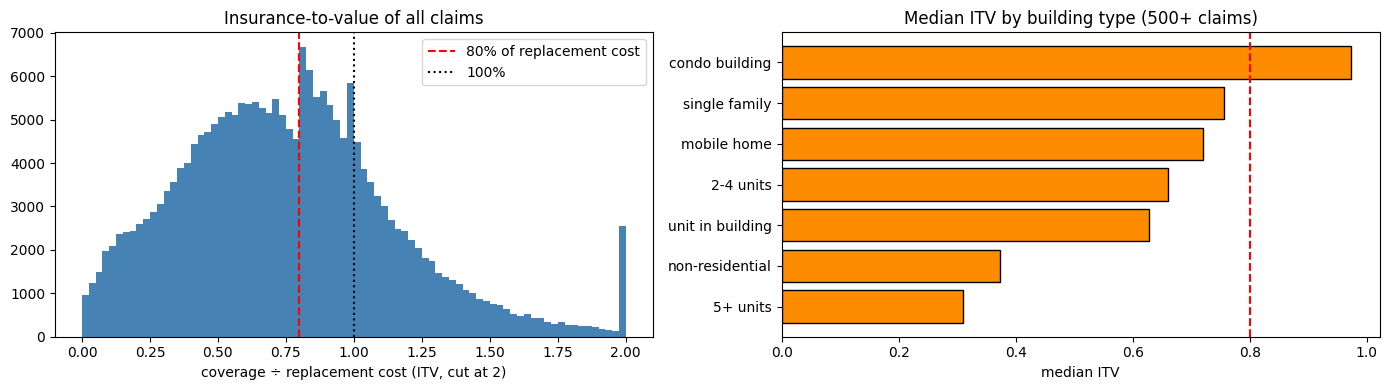

Median ITV: 0.74    share below 0.8: 55.5%    share below 0.5: 27.3%


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(d['itv'].clip(upper=2), bins=80, color='steelblue')
ax[0].axvline(0.8, color='red', ls='--', label='80% of replacement cost'); ax[0].axvline(1, color='black', ls=':', label='100%')
ax[0].set_xlabel('coverage ÷ replacement cost (ITV, cut at 2)'); ax[0].set_title('Insurance-to-value of all claims'); ax[0].legend()
by_occ = d.groupby('occupancy_name')['itv'].median().sort_values()
counts = d['occupancy_name'].value_counts()
by_occ = by_occ[counts[by_occ.index] >= 500]
ax[1].barh(by_occ.index, by_occ.values, color='darkorange', edgecolor='black'); ax[1].axvline(0.8, color='red', ls='--')
ax[1].set_xlabel('median ITV'); ax[1].set_title('Median ITV by building type (500+ claims)')
plt.tight_layout(); plt.show()
print(f"Median ITV: {d['itv'].median():.2f}    share below 0.8: {(d['itv'] < 0.8).mean():.1%}    share below 0.5: {(d['itv'] < 0.5).mean():.1%}")

**What we see**
- We can compute the ITV for **218,764 claims**. The **median ITV is 0.74**: the typical flooded building was insured for about three
  quarters of its rebuilding cost.
- **55.5%** of the claims are below 80% of the replacement cost, and **27.3%** are below half of it.
- But "below 80%" alone is not fair to the owners: a house that costs $500,000 to rebuild **cannot** be insured for more than $250,000 by the
  NFIP. The next section separates these cases.

## 3. The three groups

In [3]:
need = np.minimum(0.8 * d['buildingReplacementCost'], d['nfip_limit'])          # what the NFIP rule asks for
at_limit = d['totalBuildingInsuranceCoverage'] >= d['nfip_limit'] - 1
d['group'] = np.select([d['itv'] >= 0.8, at_limit, d['totalBuildingInsuranceCoverage'] < need],
                       ['well insured', 'at the NFIP limit', 'underinsured by choice'], 'meets the NFIP rule')
GROUPS = ['well insured', 'at the NFIP limit', 'underinsured by choice', 'meets the NFIP rule']
summary = d.groupby('group').agg(claims=('id', 'size'), median_itv=('itv', 'median'),
                                 median_replacement_cost=('buildingReplacementCost', 'median'),
                                 median_coverage=('totalBuildingInsuranceCoverage', 'median')).reindex(GROUPS).dropna(how='all')
summary['share'] = summary['claims'] / summary['claims'].sum()
summary.style.format({'claims': '{:,.0f}', 'median_itv': '{:.2f}', 'median_replacement_cost': '${:,.0f}', 'median_coverage': '${:,.0f}', 'share': '{:.1%}'})

,claims,median_itv,median_replacement_cost,median_coverage,share
group,,,,,
well insured,"97,300",1.02,"$222,808","$250,000",44.5%
at the NFIP limit,"76,108",0.53,"$490,602","$250,000",34.8%
underinsured by choice,"45,356",0.45,"$243,352","$100,000",20.7%


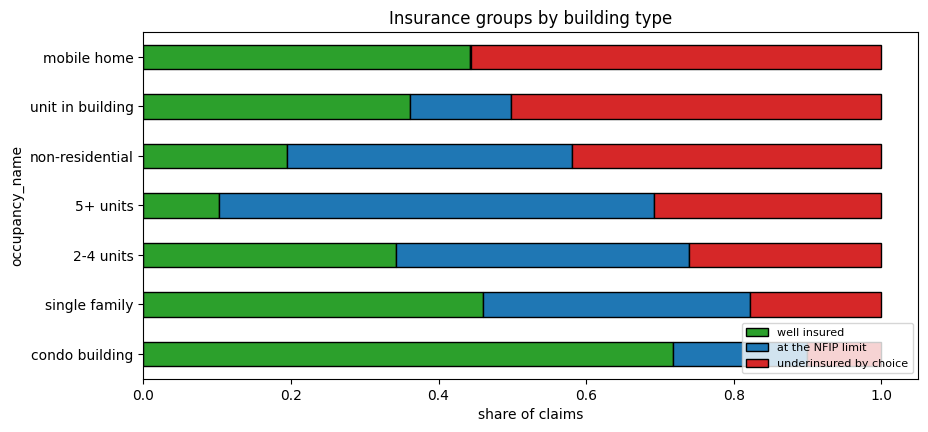

group,well insured,at the NFIP limit,underinsured by choice
occupancy_name,,,
mobile home,44.2,0.2,55.6
unit in building,36.1,13.7,50.2
non-residential,19.4,38.6,41.9
5+ units,10.2,59.0,30.8
2-4 units,34.2,39.8,26.0
single family,46.0,36.2,17.8
condo building,71.8,18.1,10.1


In [4]:
mix = pd.crosstab(d['occupancy_name'], d['group'], normalize='index').reindex(columns=[g for g in GROUPS if g in d['group'].unique()])
mix = mix[d['occupancy_name'].value_counts().reindex(mix.index) >= 500].sort_values('underinsured by choice', ascending=False)
mix.plot.barh(stacked=True, figsize=(10, 4.5), color=['#2ca02c', '#1f77b4', '#d62728', '#bbbbbb'][:mix.shape[1]], edgecolor='black')
plt.gca().invert_yaxis(); plt.xlabel('share of claims'); plt.title('Insurance groups by building type'); plt.legend(fontsize=8, loc='lower right'); plt.show()
(mix * 100).round(1)

**What we see**

| Group | Claims | Share | Median replacement cost | Median coverage |
|---|---|---|---|---|
| well insured | 97,300 | 44.5% | $222,808 | $250,000 |
| at the NFIP limit | 76,108 | 34.8% | $490,602 | $250,000 |
| underinsured by choice | 45,356 | 20.7% | $243,352 | $100,000 |

- **More than a third of the gap is not the owners' choice.** Buildings "at the NFIP limit" are expensive (median $490,602 to rebuild), and the
  NFIP simply does not sell more than $250,000 for a home.
- **One claim in five is underinsured by choice:** these buildings cost about the same as the well-insured ones ($243,352), but the owners bought
  only $100,000 of coverage (median ITV 0.45).
- **By building type:** mobile homes (55.6%) and units inside a building (50.2%) are the most often underinsured by choice; 5+ unit buildings are
  mostly at the NFIP limit (59%); condo association buildings are the best insured (71.8% well insured). Single-family homes: 46% well insured,
  36% at the limit, 18% by choice.

## 4. What does it cost? Damage that was not covered

For every claim with damage, the **uncovered damage** is the part of the building damage above the coverage:
max(damage − coverage, 0). (We ignore the deductible here, so the real gap is a little bigger.)

In [5]:
dmg = d[d['buildingDamageAmount'] > 0].copy()
dmg['uncovered'] = (dmg['buildingDamageAmount'] - dmg['totalBuildingInsuranceCoverage']).clip(lower=0)
dmg['has_gap'] = dmg['uncovered'] > 0
cost = dmg.groupby('group').agg(claims=('id', 'size'), claims_with_gap=('has_gap', 'sum'), share_with_gap=('has_gap', 'mean'),
                                uncovered_total=('uncovered', 'sum'),
                                median_gap_if_any=('uncovered', lambda s: s[s > 0].median())).reindex(GROUPS).dropna(how='all')
cost.loc['all claims'] = [len(dmg), dmg['has_gap'].sum(), dmg['has_gap'].mean(), dmg['uncovered'].sum(), dmg.loc[dmg['has_gap'], 'uncovered'].median()]
print(f"Total damage above coverage: ${dmg['uncovered'].sum() / 1e9:.2f} billion")
cost.style.format({'claims': '{:,.0f}', 'claims_with_gap': '{:,.0f}', 'share_with_gap': '{:.1%}', 'uncovered_total': '${:,.0f}', 'median_gap_if_any': '${:,.0f}'})

Total damage above coverage: $0.56 billion


,claims,claims_with_gap,share_with_gap,uncovered_total,median_gap_if_any
group,,,,,
well insured,"92,982",387,0.4%,"$62,492,698","$6,083"
at the NFIP limit,"73,820","4,445",6.0%,"$342,511,168","$19,733"
underinsured by choice,"43,163","6,311",14.6%,"$159,814,273","$11,909"
all claims,"209,965","11,143",5.3%,"$564,818,139","$13,743"


In [6]:
gap_occ = dmg.groupby('occupancy_name').agg(claims=('id', 'size'), share_with_gap=('has_gap', 'mean'), uncovered_total=('uncovered', 'sum'))
gap_occ = gap_occ[gap_occ['claims'] >= 500].sort_values('uncovered_total', ascending=False)
gap_occ['share_of_all_uncovered'] = gap_occ['uncovered_total'] / dmg['uncovered'].sum()
gap_occ.style.format({'claims': '{:,.0f}', 'share_with_gap': '{:.1%}', 'uncovered_total': '${:,.0f}', 'share_of_all_uncovered': '{:.1%}'})

,claims,share_with_gap,uncovered_total,share_of_all_uncovered
occupancy_name,,,,
non-residential,"14,465",12.4%,"$210,639,418",37.3%
single family,"163,545",4.2%,"$207,367,970",36.7%
condo building,"12,944",2.5%,"$71,135,197",12.6%
5+ units,"3,741",12.4%,"$39,916,850",7.1%
mobile home,"4,930",22.4%,"$19,567,301",3.5%
2-4 units,"9,011",5.4%,"$14,944,181",2.6%
unit in building,"1,268",6.2%,"$1,182,896",0.2%


**What we see**
- In total, **$0.56 billion** of building damage was **above the coverage** and was not paid by the NFIP (5.3% of damaged claims).
- **Most of it (61%, $343 million) belongs to buildings at the NFIP limit:** their owners could not buy more. Underinsured-by-choice buildings
  left **$160 million** uncovered (28%), and even well-insured buildings $62 million (11%; there the replacement cost was probably estimated low).
- **Underinsured by choice is the riskiest group per claim:** 14.6% of their damaged claims had damage above the coverage, against 6.0% at the
  limit and 0.4% for well-insured buildings.
- By building type, **businesses** (non-residential, $211 million, 37% of all uncovered damage) and **single-family homes** ($207 million, 37%)
  carry most of the gap. **Mobile homes** have the highest share of claims with a gap (22.4%), because their coverage is small.

## 5. Who is underinsured by choice?

We look at **homes** only (single family, 2-4 units, mobile home, unit in building), because for them the choice is clear: the NFIP limit is
$250,000. The target is 1 if the home is **underinsured by choice**. First we compare simple groups, then we train a **decision tree**
(easy to read) to see which features go together with underinsurance. The coverage and the replacement cost are **not** used as features,
because they define the target.

In [7]:
homes = d[d['occ_code'].isin([11, 12, 14, 16])].copy()
homes['by_choice'] = (homes['group'] == 'underinsured by choice').astype(int)
homes['primary_home'] = homes['primaryResidenceIndicator'].map({1: 'main home', 0: 'second home / rental'})
homes['age_group'] = pd.cut(homes['building_age'], [-1, 20, 40, 60, 200], labels=['0-20 years', '20-40', '40-60', '60+'])
homes['value_group'] = pd.qcut(homes['buildingReplacementCost'], 4, labels=['cheapest 25%', 'second', 'third', 'most expensive 25%'])
top_states = homes['state'].value_counts().head(8).index
homes['state_group'] = homes['state'].where(homes['state'].isin(top_states), 'other')
print(f"Homes: {len(homes):,}    underinsured by choice: {homes['by_choice'].mean():.1%}")
for col in ['primary_home', 'zone', 'age_group', 'value_group', 'state_group', 'rating_system']:
    t = homes.groupby(col, observed=True)['by_choice'].agg(['size', 'mean'])
    t = t[t['size'] >= 300].sort_values('mean', ascending=False)
    print(f'\n{col}:'); print(t.rename(columns={'size': 'homes', 'mean': 'share by choice'}).round(3).to_string())

Homes: 186,088    underinsured by choice: 19.6%

primary_home:
                       homes  share by choice
primary_home                                 
second home / rental   39032            0.242
main home             147056            0.183



zone:
       homes  share by choice
zone                         
A       5949            0.394
X      33708            0.211
AE    135853            0.186
A99      712            0.180
AH      2710            0.180
AO      1073            0.174
V       6003            0.137

age_group:
            homes  share by choice
age_group                         
60+         56686            0.227
40-60       68861            0.226
20-40       39002            0.141
0-20 years  21494            0.111

value_group:
                    homes  share by choice
value_group                               
cheapest 25%        46523            0.285
second              46521            0.223
third               46522            0.194
most expensive 25%  46522            0.079

state_group:
             homes  share by choice
state_group                        
PA            3250            0.445
other        30991            0.340
TX            8570            0.293
LA           20770            0.266

Decision tree (depth 3), ROC-AUC on the test part: 0.737


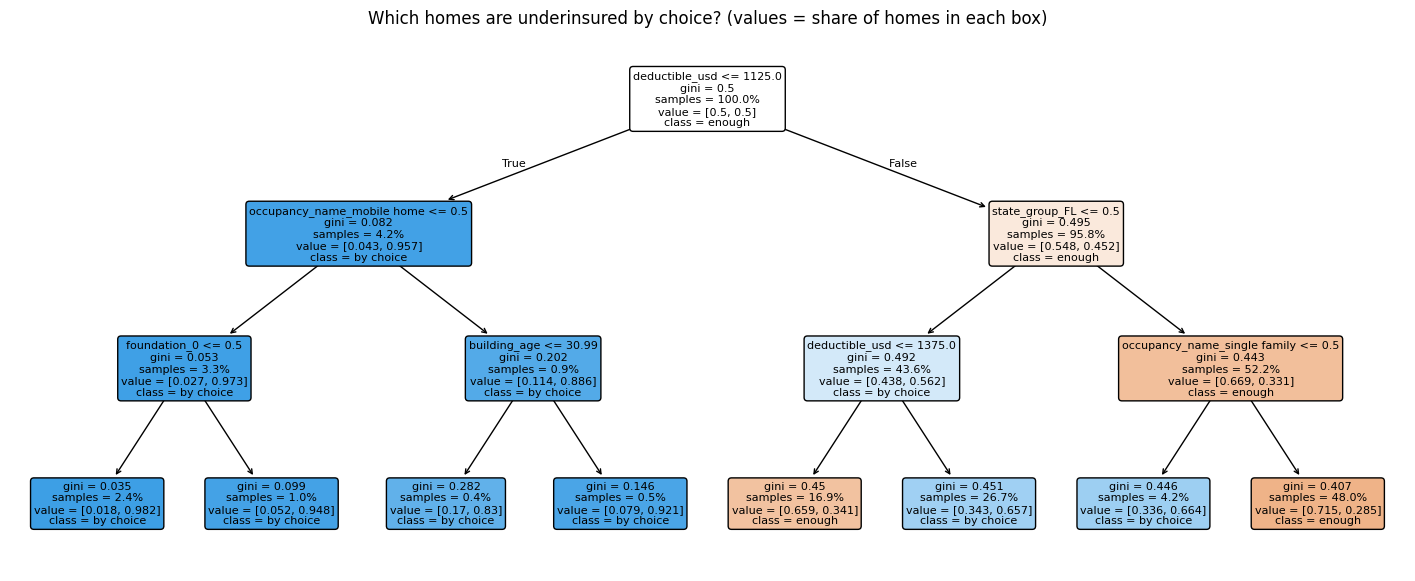

deductible_usd                  0.629
state_group_FL                  0.238
occupancy_name_single family    0.130
occupancy_name_mobile home      0.002
building_age                    0.001
foundation_0                    0.000
dtype: float64

In [8]:
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

FEATURES = ['primaryResidenceIndicator', 'building_age', 'deductible_usd', 'policyCount', 'crsClassCode', 'elevatedBuildingIndicator',
            'postFIRMConstructionIndicator', 'rentalPropertyIndicator', 'loss_year']
CAT = ['zone', 'foundation', 'state_group', 'rating_system', 'occupancy_name']
Xh = pd.get_dummies(homes[FEATURES + CAT], columns=CAT, dtype=int)
Xa, Xb, ya, yb = train_test_split(Xh, homes['by_choice'], test_size=0.3, random_state=SEED, stratify=homes['by_choice'])
tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, class_weight='balanced', random_state=SEED).fit(Xa, ya)
print(f'Decision tree (depth 3), ROC-AUC on the test part: {roc_auc_score(yb, tree.predict_proba(Xb)[:, 1]):.3f}')
plt.figure(figsize=(18, 7))
plot_tree(tree, feature_names=Xh.columns, class_names=['enough', 'by choice'], filled=True, rounded=True, fontsize=8, proportion=True)
plt.title('Which homes are underinsured by choice? (values = share of homes in each box)'); plt.show()
imp = pd.Series(tree.feature_importances_, index=Xh.columns).sort_values(ascending=False)
imp[imp > 0].round(3)

In [9]:
print('The tree uses the deductible most. Which way does it go? Share underinsured by choice, by deductible (homes):')
t = homes.groupby('deductible_usd')['by_choice'].agg(homes='size', share_by_choice='mean')
t = t[t['homes'] >= 1000]
t['median_coverage'] = homes.groupby('deductible_usd')['totalBuildingInsuranceCoverage'].median()
t.round(3)

The tree uses the deductible most. Which way does it go? Share underinsured by choice, by deductible (homes):


,homes,share_by_choice,median_coverage
deductible_usd,,,
1000.0,7957,0.844,56000.0
1250.0,57223,0.081,250000.0
1500.0,3647,0.899,60000.0
2000.0,62763,0.212,250000.0
5000.0,39388,0.153,250000.0
10000.0,14654,0.156,250000.0


**The deductible is a hidden leak.** NFIP rules link the smallest allowed deductible to the coverage amount (policies with low coverage have
the $1,000 / $1,500 deductibles). So the deductible partly *repeats* the coverage, which is part of our target. We train the tree again
**without the deductible** to see which other features matter.

Decision tree without the deductible, ROC-AUC on the test part: 0.712


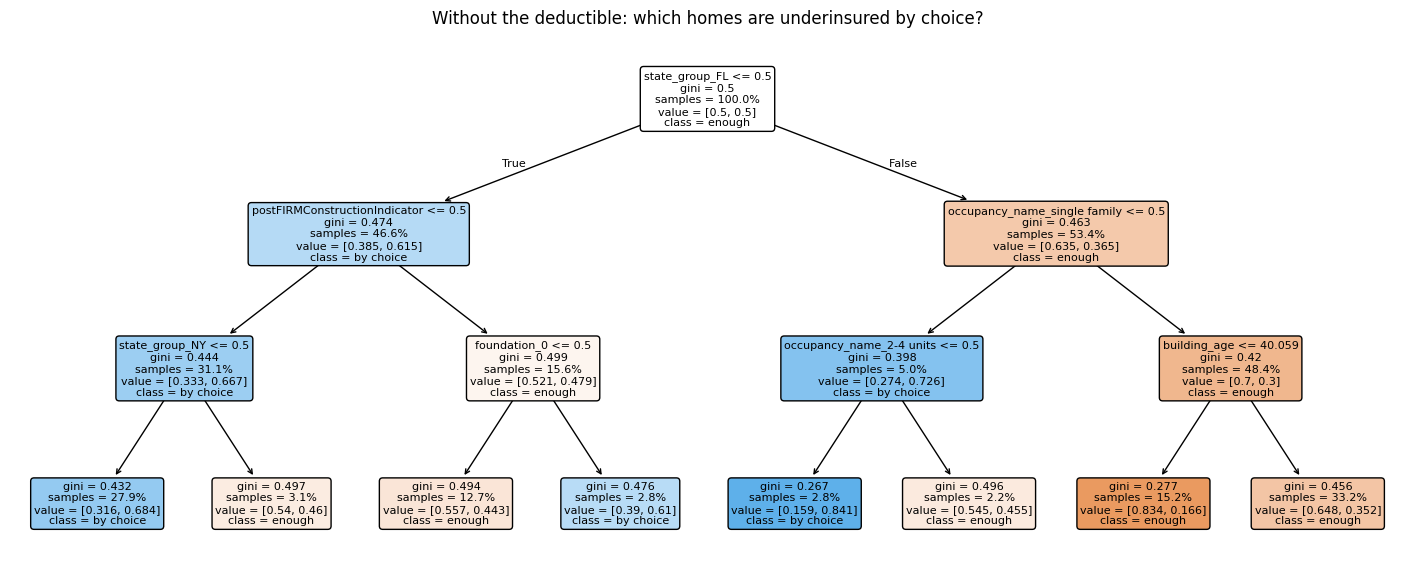

state_group_FL                   0.420
occupancy_name_single family     0.287
postFIRMConstructionIndicator    0.104
building_age                     0.073
occupancy_name_2-4 units         0.058
state_group_NY                   0.038
foundation_0                     0.019
dtype: float64

In [10]:
Xn = Xh.drop(columns=['deductible_usd'])
Xa2, Xb2, ya2, yb2 = train_test_split(Xn, homes['by_choice'], test_size=0.3, random_state=SEED, stratify=homes['by_choice'])
tree2 = DecisionTreeClassifier(max_depth=3, min_samples_leaf=500, class_weight='balanced', random_state=SEED).fit(Xa2, ya2)
print(f'Decision tree without the deductible, ROC-AUC on the test part: {roc_auc_score(yb2, tree2.predict_proba(Xb2)[:, 1]):.3f}')
plt.figure(figsize=(18, 7))
plot_tree(tree2, feature_names=Xn.columns, class_names=['enough', 'by choice'], filled=True, rounded=True, fontsize=8, proportion=True)
plt.title('Without the deductible: which homes are underinsured by choice?'); plt.show()
imp2 = pd.Series(tree2.feature_importances_, index=Xn.columns).sort_values(ascending=False)
imp2[imp2 > 0].round(3)

**What we see** (186,088 homes; 19.6% underinsured by choice)
- **Cheaper homes are underinsured much more often:** 28.5% of the cheapest quarter of homes, but only 7.9% of the most expensive quarter.
- **Older homes:** 22-23% for homes over 40 years old, 11% for homes under 20 years.
- **Second homes and rentals:** 24.2%, against 18.3% for main homes.
- **Flood zone A** (a high-risk zone without a detailed flood elevation): 39.4%, about twice zone AE (18.6%) and even more than zone X (21.1%).
- **States:** Pennsylvania (44.5%), Texas (29.3%) and Louisiana (26.6%) are high; **Florida is low (12.3%)**.
- **Legacy-rated policies:** 32.4% vs 18.2% for Risk Rating 2.0 (but remember: the rating column is the policy's *latest* rating).

**The decision tree.** The first tree found the **deductible** as the most important feature (AUC 0.737). The check shows why: homes with a
$1,000 or $1,500 deductible are 84-90% underinsured, with a median coverage of only $56,000-$60,000. These small deductibles go with small
coverage in the NFIP rules, so the deductible is a **hidden leak** of the target. **Without the deductible**, the tree still reaches an AUC of
**0.712**, and the most important features are **being in Florida** (0.42, less underinsurance), **single family** (0.29),
**post-FIRM construction** (0.10) and **building age** (0.07). So underinsurance by choice is mostly about **where** the home is and
**what kind and how old** it is.

## 6. Did it change over time or with Risk Rating 2.0?

Risk Rating 2.0 (from October 2021 for new policies, April 2022 for renewals) changed the prices. If insurance became more expensive,
some owners may have bought less coverage. We look at the median ITV and the share underinsured by choice by **loss year**.
(Remember from notebook 01: `rating_system` is the policy's latest rating, so we use the loss year here.)

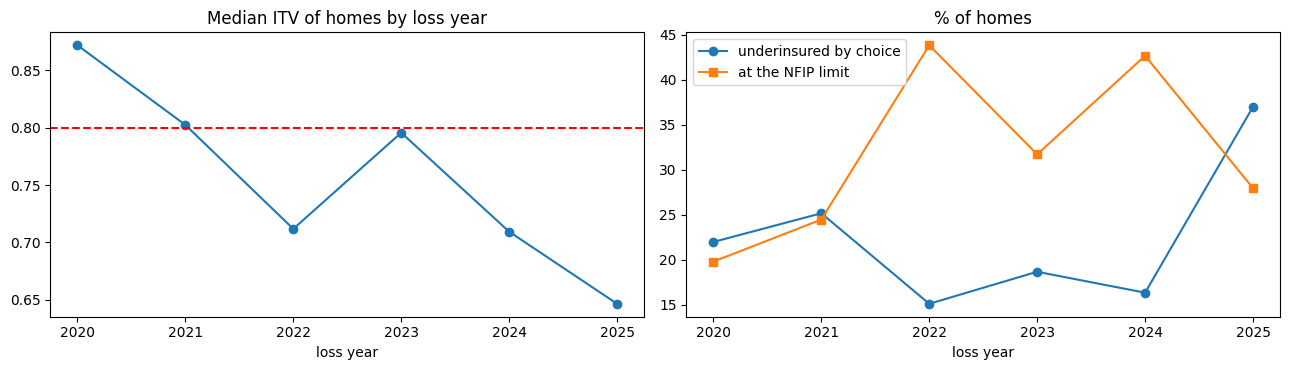

,homes,median_itv,by_choice,at_limit,median_replacement_cost
loss_year,,,,,
2020,"23,585",0.87,22.0%,19.8%,"$216,313"
2021,"32,787",0.80,25.1%,24.4%,"$243,724"
2022,"36,546",0.71,15.1%,43.8%,"$301,646"
2023,"14,629",0.80,18.6%,31.7%,"$266,200"
2024,"69,332",0.71,16.3%,42.6%,"$300,743"
2025,"9,209",0.65,37.0%,27.9%,"$264,205"


In [11]:
yr = homes.groupby('loss_year').agg(homes=('id', 'size'), median_itv=('itv', 'median'), by_choice=('by_choice', 'mean'),
                                    at_limit=('group', lambda s: (s == 'at the NFIP limit').mean()),
                                    median_replacement_cost=('buildingReplacementCost', 'median'))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(yr.index, yr['median_itv'], marker='o'); ax[0].axhline(0.8, color='red', ls='--'); ax[0].set_title('Median ITV of homes by loss year')
ax[1].plot(yr.index, yr['by_choice'] * 100, marker='o', label='underinsured by choice')
ax[1].plot(yr.index, yr['at_limit'] * 100, marker='s', label='at the NFIP limit'); ax[1].set_title('% of homes'); ax[1].legend()
for a in ax: a.set_xlabel('loss year')
plt.tight_layout(); plt.show()
yr.style.format({'homes': '{:,.0f}', 'median_itv': '{:.2f}', 'by_choice': '{:.1%}', 'at_limit': '{:.1%}', 'median_replacement_cost': '${:,.0f}'})

In [12]:
print('The storms hit different places each year, so we also look at Florida homes only:')
fl = homes[homes['state'] == 'FL'].groupby('loss_year').agg(homes=('id', 'size'), median_itv=('itv', 'median'),
                                                           by_choice=('by_choice', 'mean'), at_limit=('group', lambda s: (s == 'at the NFIP limit').mean()))
fl.round(3)

The storms hit different places each year, so we also look at Florida homes only:


,homes,median_itv,by_choice,at_limit
loss_year,,,,
2020,6890,0.937,0.094,0.256
2021,464,0.891,0.181,0.211
2022,30091,0.714,0.118,0.470
2023,7430,0.890,0.126,0.254
2024,54317,0.707,0.128,0.464
2025,255,0.690,0.137,0.514


**What we see**
- For all homes, the median ITV went from **0.87** (2020) to **0.71** (2022 and 2024). But this is mostly **not** owners buying less:
  the share **at the NFIP limit** jumped from about 20-24% to about **43-44%** in 2022 and 2024, the years of Ian, Helene and Milton.
  Those storms hit expensive homes in Florida, whose rebuilding cost is far above $250,000.
- The share **underinsured by choice** went **down** in those years (15-16%), again because the storms hit Florida, where it is low.
- **Inside Florida only**, underinsured by choice is small and quite stable: 9.4% in 2020 and about 12-13% in 2022-2024 (2021 has only 464 claims).
  The share at the limit is again what jumps (about 25% → 46-47%).
- 2025 looks very different (37% by choice), but 2025 has fewer and different claims (not complete yet), so we do not read much into it.
- **So we cannot see a clear effect of Risk Rating 2.0** on how much coverage owners bought. The changes between years come from **where the
  storms hit**. To really test Risk Rating 2.0 we would need the NFIP policy data (all policies, every year), not only the claims.

## 7. Our answer

> **More than half of flooded buildings were insured for less than 80% of their rebuilding cost (median ITV 0.74), but there are two very
> different reasons.** About a third of the claims (34.8%) are **at the NFIP limit**: expensive buildings whose owners could not buy more than
> $250,000 (or $500,000). One claim in five (20.7%) is **underinsured by choice**: the owner bought far less than allowed (median coverage
> $100,000 for a $243,000 building). In total **$0.56 billion** of damage was above the coverage; 61% of it fell on buildings at the NFIP
> limit and 28% on buildings underinsured by choice. Underinsurance by choice is most common for **cheaper, older homes, second homes and
> rentals, mobile homes, zone A**, and in **Pennsylvania, Texas and Louisiana**, and least common in Florida.

**What we learned**
- "Underinsured" needs a careful definition. Most of the gap in the big Florida hurricanes comes from the **NFIP limit**, not from owners' choices.
- A feature can leak the target in a hidden way: the deductible looked like the best predictor only because NFIP rules tie small deductibles
  to small coverage.
- **Cheaper homes are underinsured by choice 3.6 times more often than the most expensive ones** (28.5% vs 7.9%). This is a fairness question
  that could be studied further with census income data.

**Limits**
- The replacement cost is the adjuster's estimate after the flood; a wrong estimate moves a claim between groups.
- We ignore the deductible in the uncovered damage, so the real unpaid part is a bit bigger.
- We only see buildings **with a claim**. Owners with no flood insurance at all (the biggest gap) are not in the data.